Random Forest Model for Hardness Prediction

Dataset Information
Samples  : 500
Target   : Hv
Features : ['Al', 'Co', 'Cr', 'Cu', 'Fe', 'Ni']

Train-Test Split
Training samples : 400
Testing samples  : 100

Hyperparameter Optimization
Fitting 5 folds for each of 40 candidates, totalling 200 fits

Best Hyperparameters:
n_estimators        : 800
min_samples_split   : 2
min_samples_leaf    : 2
max_features        : 1.0
max_depth           : 10
bootstrap           : True

Best CV RMSE: 62.987 Hv

Model Performance

Training Set
R2   : 0.9823
RMSE : 29.906 Hv
MAE  : 21.713 Hv

Testing Set
R2   : 0.8660
RMSE : 74.637 Hv
MAE  : 49.434 Hv


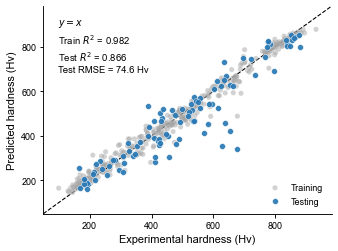


Completed

Generated Files:
1. RF_Parity_Plot.png
2. RF_Train_Test_Predictions.xlsx
3. RF_Hyperparameter_Search.csv
4. RF_Hardness_Model.joblib


In [1]:
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import (
    train_test_split,
    RandomizedSearchCV,
    KFold,
)
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error,
)


# ============================================================
# 1. Settings
# ============================================================

RANDOM_STATE = 42
TEST_SIZE = 0.20
N_ITER = 40
CV_FOLDS = 5

try:
    BASE_DIR = Path(__file__).resolve().parent
except NameError:
    BASE_DIR = Path.cwd()


# Input
DATA_FILE = BASE_DIR / "Data.xlsx"

# Outputs
MODEL_FILE = BASE_DIR / "RF_Hardness_Model.joblib"
PREDICTION_FILE = BASE_DIR / "RF_Train_Test_Predictions.xlsx"
SEARCH_FILE = BASE_DIR / "RF_Hyperparameter_Search.csv"
FIGURE_FILE = BASE_DIR / "RF_Parity_Plot.png"


# ============================================================
# 2. Load data
# ============================================================

data = pd.read_excel(DATA_FILE)

# First column = target
target_name = data.columns[0]

# Remaining columns = input features
feature_names = list(data.columns[1:])


# Remove rows containing missing values
if data.isnull().values.any():

    print("Warning: Missing values detected.")
    print(data.isnull().sum())

    data = data.dropna().reset_index(drop=True)


X = data[feature_names]
y = data[target_name]


print("=" * 60)
print("Dataset Information")
print("=" * 60)

print(f"Samples  : {len(data)}")
print(f"Target   : {target_name}")
print(f"Features : {feature_names}")


# ============================================================
# 3. Train-test split
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
)


print("\n" + "=" * 60)
print("Train-Test Split")
print("=" * 60)

print(f"Training samples : {len(X_train)}")
print(f"Testing samples  : {len(X_test)}")


# ============================================================
# 4. Random Forest and hyperparameter optimization
# ============================================================

rf = RandomForestRegressor(
    random_state=RANDOM_STATE,
    n_jobs=-1,
)


param_distributions = {

    "n_estimators": [
        200,
        300,
        400,
        500,
        600,
        700,
        800,
        900,
        1000,
        1200,
    ],

    "max_depth": [
        None,
        5,
        10,
        15,
        20,
        30,
        40,
    ],

    "min_samples_split": [
        2,
        4,
        6,
        8,
        10,
    ],

    "min_samples_leaf": [
        1,
        2,
        3,
        4,
        5,
    ],

    "max_features": [
        "sqrt",
        "log2",
        0.5,
        0.7,
        1.0,
    ],

    "bootstrap": [
        True,
        False,
    ],
}


cv = KFold(
    n_splits=CV_FOLDS,
    shuffle=True,
    random_state=RANDOM_STATE,
)


random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_distributions,
    n_iter=N_ITER,
    scoring="neg_mean_squared_error",
    cv=cv,
    n_jobs=-1,
    random_state=RANDOM_STATE,
    verbose=1,
    refit=True,
)


print("\n" + "=" * 60)
print("Hyperparameter Optimization")
print("=" * 60)


random_search.fit(
    X_train,
    y_train,
)


best_model = random_search.best_estimator_

best_cv_rmse = np.sqrt(
    -random_search.best_score_
)


print("\nBest Hyperparameters:")

for parameter, value in random_search.best_params_.items():
    print(f"{parameter:20s}: {value}")


print(
    f"\nBest CV RMSE: "
    f"{best_cv_rmse:.3f} Hv"
)


# ============================================================
# 5. Model evaluation
# ============================================================

y_train_pred = best_model.predict(X_train)
y_test_pred = best_model.predict(X_test)


def calculate_metrics(y_true, y_pred):

    return {
        "R2": r2_score(y_true, y_pred),
        "RMSE": np.sqrt(
            mean_squared_error(y_true, y_pred)
        ),
        "MAE": mean_absolute_error(
            y_true,
            y_pred
        ),
    }


train_metrics = calculate_metrics(
    y_train,
    y_train_pred,
)

test_metrics = calculate_metrics(
    y_test,
    y_test_pred,
)


print("\n" + "=" * 60)
print("Model Performance")
print("=" * 60)

print("\nTraining Set")

print(
    f"R2   : "
    f"{train_metrics['R2']:.4f}"
)

print(
    f"RMSE : "
    f"{train_metrics['RMSE']:.3f} Hv"
)

print(
    f"MAE  : "
    f"{train_metrics['MAE']:.3f} Hv"
)


print("\nTesting Set")

print(
    f"R2   : "
    f"{test_metrics['R2']:.4f}"
)

print(
    f"RMSE : "
    f"{test_metrics['RMSE']:.3f} Hv"
)

print(
    f"MAE  : "
    f"{test_metrics['MAE']:.3f} Hv"
)


# ============================================================
# 6. Save train-test predictions
# ============================================================

train_results = X_train.copy()

train_results["Actual_Hv"] = y_train.to_numpy()
train_results["Predicted_Hv"] = y_train_pred
train_results["Dataset"] = "Train"


test_results = X_test.copy()

test_results["Actual_Hv"] = y_test.to_numpy()
test_results["Predicted_Hv"] = y_test_pred
test_results["Dataset"] = "Test"


prediction_results = pd.concat(
    [
        train_results,
        test_results,
    ],
    ignore_index=True,
)


prediction_results.to_excel(
    PREDICTION_FILE,
    index=False,
)


# ============================================================
# 7. Parity plot
# ============================================================

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 9,
    "axes.labelsize": 11,
    "axes.linewidth": 0.9,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
})


fig, ax = plt.subplots(
    figsize=(5.2, 3.6)
)


# Training data
ax.scatter(
    y_train,
    y_train_pred,
    s=26,
    alpha=0.50,
    facecolor="#A6A6A6",
    edgecolor="none",
    label="Training",
    zorder=2,
)


# Testing data
ax.scatter(
    y_test,
    y_test_pred,
    s=34,
    alpha=0.92,
    facecolor="#2878B5",
    edgecolor="white",
    linewidth=0.45,
    label="Testing",
    zorder=3,
)


# Common axis range
all_actual = np.concatenate(
    [
        y_train.to_numpy(),
        y_test.to_numpy(),
    ]
)

all_predicted = np.concatenate(
    [
        y_train_pred,
        y_test_pred,
    ]
)


plot_min = min(
    all_actual.min(),
    all_predicted.min(),
)

plot_max = max(
    all_actual.max(),
    all_predicted.max(),
)


padding = (
    plot_max
    - plot_min
) * 0.06


plot_min -= padding
plot_max += padding


# y = x reference line
ax.plot(
    [plot_min, plot_max],
    [plot_min, plot_max],
    "--",
    color="black",
    linewidth=1.1,
    zorder=1,
)


ax.set_xlim(
    plot_min,
    plot_max,
)

ax.set_ylim(
    plot_min,
    plot_max,
)


# Rectangular layout suitable for presentation
ax.set_box_aspect(0.72)


ax.set_xlabel(
    "Experimental hardness (Hv)"
)

ax.set_ylabel(
    "Predicted hardness (Hv)"
)


# Nature-style axes
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.tick_params(
    axis="both",
    direction="out",
    width=0.9,
    length=3.5,
)


# Performance information
performance_text = (
    "$y=x$\n"
    f"Train $R^2$ = {train_metrics['R2']:.3f}\n"
    f"Test $R^2$ = {test_metrics['R2']:.3f}\n"
    f"Test RMSE = {test_metrics['RMSE']:.1f} Hv"
)


ax.text(
    0.05,
    0.95,
    performance_text,
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=9.5,
    linespacing=1.3,
)


ax.legend(
    loc="lower right",
    frameon=False,
)


ax.grid(False)

plt.tight_layout()


plt.savefig(
    FIGURE_FILE,
    dpi=600,
    bbox_inches="tight",
    facecolor="white",
)


plt.show()


# ============================================================
# 8. Save hyperparameter search results
# ============================================================

search_results = pd.DataFrame(
    random_search.cv_results_
)

search_results = search_results.sort_values(
    "rank_test_score"
)


search_results.to_csv(
    SEARCH_FILE,
    index=False,
)


# ============================================================
# 9. Train final model using the complete dataset
# ============================================================

final_model = RandomForestRegressor(
    **random_search.best_params_,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)


final_model.fit(
    X,
    y,
)


# ============================================================
# 10. Save final model
# ============================================================

model_package = {

    "model": final_model,

    "features": feature_names,

    "target": target_name,

    "best_params": random_search.best_params_,

    "cv_rmse": best_cv_rmse,

    "random_state": RANDOM_STATE,
}


joblib.dump(
    model_package,
    MODEL_FILE,
)


# ============================================================
# 11. Summary
# ============================================================

print("\n" + "=" * 60)
print("Completed")
print("=" * 60)

print("\nGenerated Files:")

print(
    f"1. {FIGURE_FILE.name}"
)

print(
    f"2. {PREDICTION_FILE.name}"
)

print(
    f"3. {SEARCH_FILE.name}"
)

print(
    f"4. {MODEL_FILE.name}"
)

Alloy Composition Design Space Generation

In [2]:
from pathlib import Path

import pandas as pd


# ============================================================
# 1. Settings
# ============================================================

STEP = 1          # Composition resolution (at.%)
CHUNK_SIZE = 100_000

try:
    BASE_DIR = Path(__file__).resolve().parent
except NameError:
    BASE_DIR = Path.cwd()


OUTPUT_FILE = BASE_DIR / "Design_Space.csv"


# ============================================================
# 2. Composition ranges
# ============================================================
#
# Constraints:
#
# 15 < Al < 47
# 5  < Co < 22
# 6  < Cr < 34
# 5  < Cu < 16
# 5  < Fe < 31
# 5  < Ni < 22
#
# With STEP = 1 at.%:
#
# Al = 16–46
# Co = 6–21
# Cr = 7–33
# Cu = 6–15
# Fe = 6–30
# Ni = 6–21
#
# Additional constraint:
#
# Al + Co + Cr + Cu + Fe + Ni = 100 at.%
#
# ============================================================

al_range = range(16, 47, STEP)
co_range = range(6, 22, STEP)
cr_range = range(7, 34, STEP)
cu_range = range(6, 16, STEP)
fe_range = range(6, 31, STEP)

ni_min = 6
ni_max = 21

columns = [
    "Al",
    "Co",
    "Cr",
    "Cu",
    "Fe",
    "Ni",
]


# ============================================================
# 3. Generate design space
# ============================================================

print("=" * 60)
print("Generating Alloy Design Space")
print("=" * 60)


buffer = []

total_candidates = 0
first_write = True


for al in al_range:

    for co in co_range:

        for cr in cr_range:

            for cu in cu_range:

                for fe in fe_range:

                    # Ni is determined by the 100 at.% constraint
                    ni = 100 - (
                        al
                        + co
                        + cr
                        + cu
                        + fe
                    )

                    # Keep only candidates satisfying the Ni range
                    if ni_min <= ni <= ni_max:

                        buffer.append([
                            al,
                            co,
                            cr,
                            cu,
                            fe,
                            ni,
                        ])

                        total_candidates += 1


                    # ------------------------------------------------
                    # Write candidates in chunks to limit memory usage
                    # ------------------------------------------------

                    if len(buffer) >= CHUNK_SIZE:

                        chunk = pd.DataFrame(
                            buffer,
                            columns=columns,
                        )

                        chunk.to_csv(
                            OUTPUT_FILE,
                            mode="w" if first_write else "a",
                            header=first_write,
                            index=False,
                        )

                        first_write = False
                        buffer.clear()

                        print(
                            f"{total_candidates:,} "
                            f"candidates generated"
                        )


# ============================================================
# 4. Save remaining candidates
# ============================================================

if buffer:

    chunk = pd.DataFrame(
        buffer,
        columns=columns,
    )

    chunk.to_csv(
        OUTPUT_FILE,
        mode="w" if first_write else "a",
        header=first_write,
        index=False,
    )


# ============================================================
# 5. Summary
# ============================================================

print("\n" + "=" * 60)
print("Design Space Generation Completed")
print("=" * 60)

print(
    f"Total candidates : "
    f"{total_candidates:,}"
)

print(
    f"Step size        : "
    f"{STEP} at.%"
)

print(
    f"Output file      : "
    f"{OUTPUT_FILE.name}"
)

Generating Alloy Design Space
100,000 candidates generated
200,000 candidates generated
300,000 candidates generated
400,000 candidates generated
500,000 candidates generated
600,000 candidates generated
700,000 candidates generated
800,000 candidates generated
900,000 candidates generated
1,000,000 candidates generated
1,100,000 candidates generated
1,200,000 candidates generated

Design Space Generation Completed
Total candidates : 1,224,117
Step size        : 1 at.%
Output file      : Design_Space.csv


Random Forest Prediction and Hardness Distribution Analysis

Loading Random Forest Model
Target   : Hv
Features : ['Al', 'Co', 'Cr', 'Cu', 'Fe', 'Ni']

Design space validated successfully.

Predicting Alloy Design Space
Chunk   1 | Processed 100,000 | Best Hv 589.01 | 1.3 s
Chunk   2 | Processed 200,000 | Best Hv 593.45 | 2.6 s
Chunk   3 | Processed 300,000 | Best Hv 609.09 | 3.9 s
Chunk   4 | Processed 400,000 | Best Hv 653.18 | 5.2 s
Chunk   5 | Processed 500,000 | Best Hv 661.35 | 6.6 s
Chunk   6 | Processed 600,000 | Best Hv 664.03 | 7.7 s
Chunk   7 | Processed 700,000 | Best Hv 669.85 | 9.1 s
Chunk   8 | Processed 800,000 | Best Hv 675.77 | 10.4 s
Chunk   9 | Processed 900,000 | Best Hv 678.07 | 11.6 s
Chunk  10 | Processed 1,000,000 | Best Hv 741.20 | 12.8 s
Chunk  11 | Processed 1,100,000 | Best Hv 773.89 | 13.9 s
Chunk  12 | Processed 1,200,000 | Best Hv 829.66 | 15.0 s
Chunk  13 | Processed 1,224,117 | Best Hv 832.45 | 15.3 s

Design-Space Prediction Completed
Candidates predicted : 1,224,117
Candidates retained  : 1,000
Highest predict

C:\Users\LIBINZ~1\AppData\Local\Temp/ipykernel_23276/3575263165.py:803: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


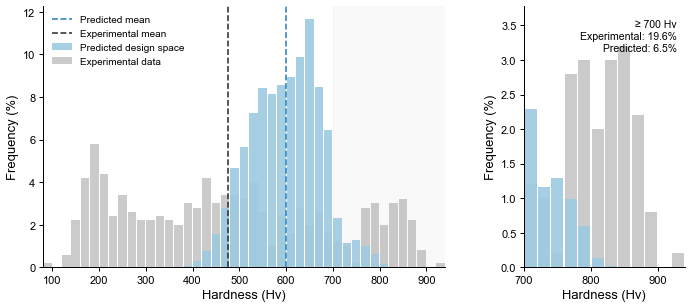


High-Hardness Region
Experimental samples ≥ 700 Hv : 98 (19.60%)
Predicted samples ≥ 700 Hv : 79,609 (6.50%)

Generated Files:
1. RF_DesignSpace_Predictions.csv
2. RF_Top1000_Candidates.xlsx
3. RF_Hardness_Distribution.png

Top 20 Predicted Candidates
 Rank  Al  Co  Cr  Cu  Fe  Ni  Predicted_Hv
    1  46  17  17   6   7   7    832.450891
    2  46  16  18   6   7   7    832.020609
    3  45  16  20   6   7   6    831.938490
    4  45  16  20   6   6   7    831.917155
    5  45  16  19   6   7   7    831.797905
    6  46  17  18   6   6   7    831.516680
    7  46  16  19   6   6   7    831.503427
    8  45  17  18   6   7   7    831.424583
    9  46  16  20   6   6   6    830.954598
   10  46  16  19   6   7   6    830.502286
   11  45  17  20   6   6   6    830.494208
   12  45  17  19   6   6   7    830.377155
   13  46  17  18   6   7   6    830.206996
   14  46  17  19   6   6   6    829.914967
   15  45  17  19   6   7   6    829.823206
   16  46  16  17   6   7   8    829.730521

In [4]:
from pathlib import Path
from time import perf_counter

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec


# ============================================================
# 1. Settings
# ============================================================

CHUNK_SIZE = 100_000
TOP_N = 1000

HIGH_HV_THRESHOLD = 700
BIN_WIDTH = 20


try:
    BASE_DIR = Path(__file__).resolve().parent
except NameError:
    BASE_DIR = Path.cwd()


# Input files
DATA_FILE = BASE_DIR / "Data.xlsx"
MODEL_FILE = BASE_DIR / "RF_Hardness_Model.joblib"
DESIGN_SPACE_FILE = BASE_DIR / "Design_Space.csv"

# Output files
PREDICTION_FILE = BASE_DIR / "RF_DesignSpace_Predictions.csv"
TOP_CANDIDATES_FILE = BASE_DIR / "RF_Top1000_Candidates.xlsx"
FIGURE_FILE = BASE_DIR / "RF_Hardness_Distribution.png"


# ============================================================
# 2. Load trained Random Forest model
# ============================================================

print("=" * 65)
print("Loading Random Forest Model")
print("=" * 65)


model_package = joblib.load(MODEL_FILE)


required_keys = {
    "model",
    "features",
    "target",
}


missing_keys = (
    required_keys
    - set(model_package.keys())
)


if missing_keys:
    raise KeyError(
        f"Missing keys in model package: "
        f"{sorted(missing_keys)}"
    )


model = model_package["model"]
feature_names = model_package["features"]
target_name = model_package["target"]


print(f"Target   : {target_name}")
print(f"Features : {feature_names}")


# ============================================================
# 3. Validate design space
# ============================================================

design_columns = pd.read_csv(
    DESIGN_SPACE_FILE,
    nrows=1,
).columns.tolist()


missing_features = [
    feature
    for feature in feature_names
    if feature not in design_columns
]


if missing_features:
    raise ValueError(
        f"Missing features in design space: "
        f"{missing_features}"
    )


print("\nDesign space validated successfully.")


# ============================================================
# 4. Prepare prediction output
# ============================================================

if PREDICTION_FILE.exists():
    PREDICTION_FILE.unlink()


top_candidates = pd.DataFrame()

predicted_values = []

first_chunk = True
total_processed = 0

start_time = perf_counter()


# ============================================================
# 5. Predict entire design space
# ============================================================

print("\n" + "=" * 65)
print("Predicting Alloy Design Space")
print("=" * 65)


for chunk_index, chunk in enumerate(
    pd.read_csv(
        DESIGN_SPACE_FILE,
        chunksize=CHUNK_SIZE,
    ),
    start=1,
):

    # --------------------------------------------------------
    # Predict hardness
    # --------------------------------------------------------

    X_candidate = chunk[feature_names]

    predicted_hv = model.predict(
        X_candidate
    )


    chunk["Predicted_Hv"] = predicted_hv


    # Keep predicted values for subsequent distribution analysis
    predicted_values.append(
        predicted_hv
    )


    # --------------------------------------------------------
    # Save complete prediction results
    # --------------------------------------------------------

    chunk.to_csv(
        PREDICTION_FILE,
        mode="w" if first_chunk else "a",
        header=first_chunk,
        index=False,
    )


    first_chunk = False


    # --------------------------------------------------------
    # Update global Top-N candidates
    # --------------------------------------------------------

    chunk_top = chunk.nlargest(
        TOP_N,
        "Predicted_Hv",
    )


    top_candidates = pd.concat(
        [
            top_candidates,
            chunk_top,
        ],
        ignore_index=True,
    )


    top_candidates = top_candidates.nlargest(
        TOP_N,
        "Predicted_Hv",
    )


    # --------------------------------------------------------
    # Progress
    # --------------------------------------------------------

    total_processed += len(chunk)

    elapsed_time = (
        perf_counter()
        - start_time
    )


    print(
        f"Chunk {chunk_index:>3d} | "
        f"Processed {total_processed:,} | "
        f"Best Hv "
        f"{top_candidates['Predicted_Hv'].max():.2f} | "
        f"{elapsed_time:.1f} s"
    )


# ============================================================
# 6. Rank and save Top-N candidates
# ============================================================

top_candidates = (
    top_candidates
    .sort_values(
        "Predicted_Hv",
        ascending=False,
    )
    .reset_index(drop=True)
)


top_candidates.insert(
    0,
    "Rank",
    range(
        1,
        len(top_candidates) + 1,
    ),
)


output_columns = (
    ["Rank"]
    + feature_names
    + ["Predicted_Hv"]
)


top_candidates = top_candidates[
    output_columns
]


top_candidates.to_excel(
    TOP_CANDIDATES_FILE,
    index=False,
)


# ============================================================
# 7. Prediction summary
# ============================================================

elapsed_time = (
    perf_counter()
    - start_time
)


print("\n" + "=" * 65)
print("Design-Space Prediction Completed")
print("=" * 65)

print(
    f"Candidates predicted : "
    f"{total_processed:,}"
)

print(
    f"Candidates retained  : "
    f"{len(top_candidates):,}"
)

print(
    f"Highest predicted Hv : "
    f"{top_candidates['Predicted_Hv'].iloc[0]:.2f}"
)

print(
    f"Top-{TOP_N} cutoff Hv : "
    f"{top_candidates['Predicted_Hv'].iloc[-1]:.2f}"
)

print(
    f"Calculation time     : "
    f"{elapsed_time:.1f} s"
)


# ============================================================
# 8. Prepare hardness data for visualization
# ============================================================

experimental_data = pd.read_excel(
    DATA_FILE
)


if target_name not in experimental_data.columns:
    raise ValueError(
        f"Target column '{target_name}' "
        f"not found in {DATA_FILE.name}"
    )


experimental_hv = (
    experimental_data[target_name]
    .dropna()
    .to_numpy()
)


predicted_hv = np.concatenate(
    predicted_values
)


print("\n" + "=" * 65)
print("Hardness Distribution")
print("=" * 65)

print(
    f"Experimental samples : "
    f"{len(experimental_hv):,}"
)

print(
    f"Predicted candidates : "
    f"{len(predicted_hv):,}"
)

print(
    f"Experimental range   : "
    f"{experimental_hv.min():.2f}–"
    f"{experimental_hv.max():.2f} Hv"
)

print(
    f"Predicted range      : "
    f"{predicted_hv.min():.2f}–"
    f"{predicted_hv.max():.2f} Hv"
)


# ============================================================
# 9. Common histogram bins
# ============================================================

hv_min = np.floor(
    min(
        experimental_hv.min(),
        predicted_hv.min(),
    )
    / BIN_WIDTH
) * BIN_WIDTH


hv_max = np.ceil(
    max(
        experimental_hv.max(),
        predicted_hv.max(),
    )
    / BIN_WIDTH
) * BIN_WIDTH


bins = np.arange(
    hv_min,
    hv_max + BIN_WIDTH,
    BIN_WIDTH,
)


bin_centers = (
    bins[:-1]
    + bins[1:]
) / 2


# ============================================================
# 10. Frequency distributions
# ============================================================
#
# Each dataset is independently normalized to 100%.
#
# ============================================================

experimental_count, _ = np.histogram(
    experimental_hv,
    bins=bins,
)


predicted_count, _ = np.histogram(
    predicted_hv,
    bins=bins,
)


experimental_frequency = (
    experimental_count
    / len(experimental_hv)
    * 100
)


predicted_frequency = (
    predicted_count
    / len(predicted_hv)
    * 100
)


# ============================================================
# 11. Distribution statistics
# ============================================================

experimental_mean = np.mean(
    experimental_hv
)


predicted_mean = np.mean(
    predicted_hv
)


experimental_high_count = np.sum(
    experimental_hv
    >= HIGH_HV_THRESHOLD
)


predicted_high_count = np.sum(
    predicted_hv
    >= HIGH_HV_THRESHOLD
)


experimental_high_fraction = (
    experimental_high_count
    / len(experimental_hv)
    * 100
)


predicted_high_fraction = (
    predicted_high_count
    / len(predicted_hv)
    * 100
)


print(
    f"\nExperimental mean Hv : "
    f"{experimental_mean:.2f}"
)

print(
    f"Predicted mean Hv    : "
    f"{predicted_mean:.2f}"
)


# ============================================================
# 12. Figure style
# ============================================================

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 11,
    "axes.linewidth": 1.0,
    "axes.labelsize": 13,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 10,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "xtick.major.width": 1.0,
    "ytick.major.width": 1.0,
    "xtick.major.size": 4,
    "ytick.major.size": 4,
})


PREDICTED_COLOR = "#9ecae1"
PREDICTED_ALPHA = 0.90

EXPERIMENTAL_COLOR = "#7f7f7f"
EXPERIMENTAL_ALPHA = 0.40


# ============================================================
# 13. Create figure
# ============================================================

fig = plt.figure(
    figsize=(11.5, 4.8)
)


grid = GridSpec(
    1,
    2,
    width_ratios=[
        2.5,
        1.0,
    ],
    wspace=0.28,
)


ax = fig.add_subplot(
    grid[0]
)


ax_zoom = fig.add_subplot(
    grid[1]
)


bar_width = (
    BIN_WIDTH
    * 0.90
)


# ============================================================
# 14. Full hardness distribution
# ============================================================

# Experimental data
ax.bar(
    bin_centers,
    experimental_frequency,
    width=bar_width,
    color=EXPERIMENTAL_COLOR,
    alpha=EXPERIMENTAL_ALPHA,
    edgecolor="none",
    label="Experimental data",
    zorder=1,
)


# Predicted design space
ax.bar(
    bin_centers,
    predicted_frequency,
    width=bar_width,
    color=PREDICTED_COLOR,
    alpha=PREDICTED_ALPHA,
    edgecolor="none",
    label="Predicted design space",
    zorder=2,
)


# Mean values
ax.axvline(
    predicted_mean,
    linestyle="--",
    linewidth=1.6,
    color="#3182bd",
    label="Predicted mean",
    zorder=4,
)


ax.axvline(
    experimental_mean,
    linestyle="--",
    linewidth=1.6,
    color="#333333",
    label="Experimental mean",
    zorder=4,
)


# Highlight high-hardness region
ax.axvspan(
    HIGH_HV_THRESHOLD,
    hv_max,
    color="black",
    alpha=0.025,
    zorder=0,
)


ax.set_xlabel(
    "Hardness (Hv)"
)

ax.set_ylabel(
    "Frequency (%)"
)


ax.set_xlim(
    hv_min,
    hv_max,
)

ax.set_ylim(
    bottom=0,
)


ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)


# ============================================================
# 15. Legend
# ============================================================

handles, labels = (
    ax.get_legend_handles_labels()
)


legend_order = [
    "Predicted mean",
    "Experimental mean",
    "Predicted design space",
    "Experimental data",
]


ordered_handles = []
ordered_labels = []


for label in legend_order:

    if label in labels:

        index = labels.index(label)

        ordered_handles.append(
            handles[index]
        )

        ordered_labels.append(
            labels[index]
        )


ax.legend(
    ordered_handles,
    ordered_labels,
    loc="upper left",
    frameon=False,
    handlelength=2.0,
)


# ============================================================
# 16. High-hardness region
# ============================================================

high_mask = (
    bin_centers
    >= HIGH_HV_THRESHOLD
)


high_bin_centers = bin_centers[
    high_mask
]


high_experimental_frequency = (
    experimental_frequency[
        high_mask
    ]
)


high_predicted_frequency = (
    predicted_frequency[
        high_mask
    ]
)


# Experimental data
ax_zoom.bar(
    high_bin_centers,
    high_experimental_frequency,
    width=bar_width,
    color=EXPERIMENTAL_COLOR,
    alpha=EXPERIMENTAL_ALPHA,
    edgecolor="none",
    zorder=1,
)


# Predicted design space
ax_zoom.bar(
    high_bin_centers,
    high_predicted_frequency,
    width=bar_width,
    color=PREDICTED_COLOR,
    alpha=PREDICTED_ALPHA,
    edgecolor="none",
    zorder=2,
)


ax_zoom.set_xlim(
    HIGH_HV_THRESHOLD,
    hv_max,
)


ax_zoom.set_xlabel(
    "Hardness (Hv)"
)

ax_zoom.set_ylabel(
    "Frequency (%)"
)


ax_zoom.spines["top"].set_visible(False)
ax_zoom.spines["right"].set_visible(False)


# ============================================================
# 17. Zoom-panel Y range
# ============================================================

high_max = max(
    (
        high_experimental_frequency.max()
        if len(high_experimental_frequency) > 0
        else 0
    ),
    (
        high_predicted_frequency.max()
        if len(high_predicted_frequency) > 0
        else 0
    ),
)


if high_max > 0:

    ax_zoom.set_ylim(
        0,
        high_max * 1.18,
    )


# ============================================================
# 18. High-hardness statistics
# ============================================================

statistics_text = (
    f"≥ {HIGH_HV_THRESHOLD} Hv\n"
    f"Experimental: "
    f"{experimental_high_fraction:.1f}%\n"
    f"Predicted: "
    f"{predicted_high_fraction:.1f}%"
)


ax_zoom.text(
    0.95,
    0.95,
    statistics_text,
    transform=ax_zoom.transAxes,
    ha="right",
    va="top",
    fontsize=10.5,
)


# ============================================================
# 19. Save figure
# ============================================================

plt.tight_layout()


plt.savefig(
    FIGURE_FILE,
    dpi=600,
    bbox_inches="tight",
    facecolor="white",
)


plt.show()


# ============================================================
# 20. Final summary
# ============================================================

print("\n" + "=" * 65)
print("High-Hardness Region")
print("=" * 65)

print(
    f"Experimental samples ≥ "
    f"{HIGH_HV_THRESHOLD} Hv : "
    f"{experimental_high_count:,} "
    f"({experimental_high_fraction:.2f}%)"
)

print(
    f"Predicted samples ≥ "
    f"{HIGH_HV_THRESHOLD} Hv : "
    f"{predicted_high_count:,} "
    f"({predicted_high_fraction:.2f}%)"
)


print("\nGenerated Files:")

print(
    f"1. {PREDICTION_FILE.name}"
)

print(
    f"2. {TOP_CANDIDATES_FILE.name}"
)

print(
    f"3. {FIGURE_FILE.name}"
)


print("\n" + "=" * 65)
print("Top 20 Predicted Candidates")
print("=" * 65)

print(
    top_candidates
    .head(20)
    .to_string(index=False)
)